## Ice Task 2 PDAN8412

Building an ANN from scratch like we did in class. It starts with the sigmoid function and then the same network is trained with ReLU, Tanh and Softmax so the learning curves can be compared.

#### Setting up Spark and the data

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions
import os
import sys
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

In [2]:
spark = SparkSession.builder\
.master("local")\
.appName("Neural Network Model")\
.config("spark.executor.memory",'6gb')\
.getOrCreate()

sc = spark.sparkContext

26/09/30 16:17:17 WARN Utils: Your hostname, Ayushs-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.10.191 instead (on interface en0)
26/09/30 16:17:17 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/09/30 16:17:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
df = spark.createDataFrame([('Male', 67, 150), ('Female', 65, 135), ('Female', 68, 130),
                            ('Male', 70, 160), ('Female', 70, 130), ('Male', 69, 174),
                            ('Female', 65, 126), ('Male', 74, 188), ('Female', 60, 110),
                            ('Female', 63, 125), ('Male', 70, 173), ('Male', 70, 145),
                            ('Male', 68, 175), ('Female', 65, 123), ('Male', 71, 145),
                            ('Male', 74, 160), ('Female', 64, 135), ('Male', 71, 175),
                            ('Male', 67, 145), ('Female', 67, 130), ('Male', 70, 162),
                            ('Female', 64, 107), ('Male', 70, 175), ('Female', 64, 130),
                            ('Male', 66, 163), ('Female', 63, 137), ('Male', 65, 165),
                            ('Female', 65, 130), ('Female', 64, 109)], ['gender', 'height', 'weight'])
df.show(10)

+------+------+------+
|gender|height|weight|
+------+------+------+
|  Male|    67|   150|
|Female|    65|   135|
|Female|    68|   130|
|  Male|    70|   160|
|Female|    70|   130|
|  Male|    69|   174|
|Female|    65|   126|
|  Male|    74|   188|
|Female|    60|   110|
|Female|    63|   125|
+------+------+------+
only showing top 10 rows



In [4]:
#Female = 0 and Male = 1
df = df.withColumn('gender', functions.when(df['gender'] == 'Female', 0).otherwise(1))
df = df.select('height', 'weight', 'gender')
df.show(10)

+------+------+------+
|height|weight|gender|
+------+------+------+
|    67|   150|     1|
|    65|   135|     0|
|    68|   130|     0|
|    70|   160|     1|
|    70|   130|     0|
|    69|   174|     1|
|    65|   126|     0|
|    74|   188|     1|
|    60|   110|     0|
|    63|   125|     0|
+------+------+------+
only showing top 10 rows



In [5]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

array = np.array(df.collect())
print(array.shape)

(29, 3)


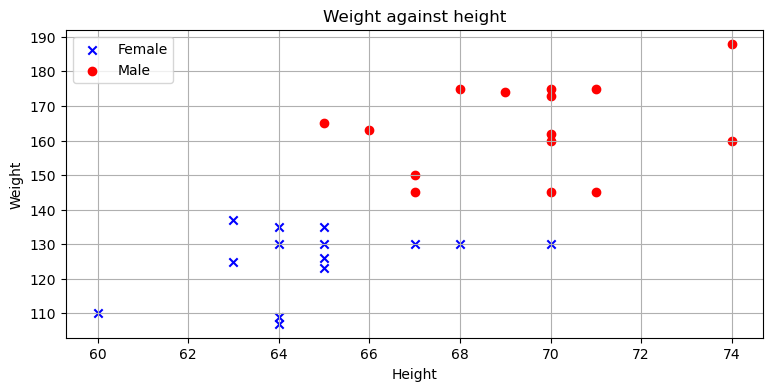

In [6]:
height = array[:, 0]
weight = array[:, 1]
gender = array[:, 2]

plt.figure(figsize = (9, 4))
plt.scatter(height[gender == 0], weight[gender == 0], marker = 'x', c = 'b', label = 'Female')
plt.scatter(height[gender == 1], weight[gender == 1], marker = 'o', c = 'r', label = 'Male')
plt.title("Weight against height")
plt.xlabel("Height")
plt.ylabel("Weight")
plt.legend()
plt.grid()
plt.show()

#### Normalising the features

In [7]:
x = array[:, :2] #Features (height, weight)
y_true = array[:, 2] #True labels (gender)

x_mean = x.mean(axis = 0)
x_std = x.std(axis = 0)

x = (x - x_mean) / x_std

array = np.column_stack((x, y_true))
print(array[:5])

[[-0.06163661  0.21460055  1.        ]
 [-0.65745714 -0.4618577   0.        ]
 [ 0.23627366 -0.68734378  0.        ]
 [ 0.8320942   0.66557271  1.        ]
 [ 0.8320942  -0.68734378  0.        ]]


#### Training function

In class the training loop was written out for sigmoid only. To test four activation functions without copying the loop four times, the loop is put into a function that takes the activation function and its derivative. Everything else stays the same as class: 2 inputs, 1 output neuron, squared error cost, stochastic gradient descent, learning rate of 0.1 and 100000 iterations. The same random seed is used every time so each activation starts from the same weights and sees the same people in the same order, which keeps the comparison fair.

In [8]:
learning_rate = 0.1
iterations = 100000

def train(activation, activation_derivative):
    np.random.seed(12345)
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    all_costs = []

    for i in range(iterations):
        random_number = np.random.randint(len(array))
        random_person = array[random_number]

        height = random_person[0]
        weight = random_person[1]
        actualGender = random_person[2]

        z = (w1*height) + (w2*weight) + b
        predictedGender = activation(z)

        cost = (predictedGender - actualGender)**2
        all_costs.append(cost)

        #Chain rule
        dcost_dpredictedGender = 2*(predictedGender - actualGender)
        dpredictedGender_dz = activation_derivative(z)

        dcost_dw1 = dcost_dpredictedGender * dpredictedGender_dz * height
        dcost_dw2 = dcost_dpredictedGender * dpredictedGender_dz * weight
        dcost_db = dcost_dpredictedGender * dpredictedGender_dz * 1

        #Gradient descent
        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return w1, w2, b, all_costs

Helper functions for plotting the learning curve and checking the accuracy. The cost for a single person jumps around a lot because it is stochastic gradient descent, so a moving average of the last 1000 costs is drawn on top to make the trend easier to see.

In [9]:
def plot_learning_curve(all_costs, name):
    moving_average = np.convolve(all_costs, np.ones(1000)/1000, mode = 'valid')

    plt.figure(figsize = (9, 4))
    plt.plot(all_costs, alpha = 0.3, label = 'Cost per iteration')
    plt.plot(moving_average, c = 'r', label = 'Moving average (1000)')
    plt.title(f"{name}: Cost over {iterations} iterations")
    plt.xlabel("Iterations")
    plt.ylabel("Cost value")
    plt.legend()
    plt.show()

def accuracy(predictions):
    predicted_labels = (np.array(predictions) > 0.5).astype(int)
    return (predicted_labels == array[:, 2]).mean()

results = {}

### Experiment 1: Sigmoid

Sigmoid squashes any number into a value between 0 and 1, which works well as a probability for Male.

In [10]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    return sigmoid(z) * (1 - sigmoid(z))

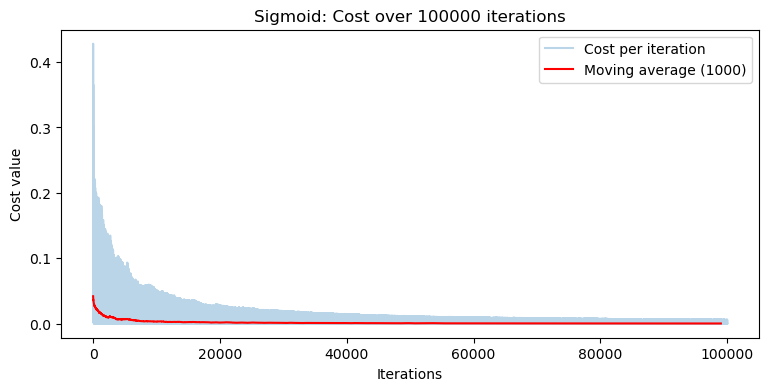

In [11]:
w1, w2, b, sigmoid_costs = train(sigmoid, sigmoid_derivative)
plot_learning_curve(sigmoid_costs, "Sigmoid")

In [12]:
sigmoid_predictions = [sigmoid(w1*p[0] + w2*p[1] + b) for p in array]
results['Sigmoid'] = (sigmoid_costs, accuracy(sigmoid_predictions))
print('w1:', w1, ' w2:', w2, ' b:', b)
print('Accuracy:', results['Sigmoid'][1])

w1: 1.8207834497316182  w2: 10.501523489170982  b: 2.691173312112982
Accuracy: 1.0


### Experiment 2: ReLU

ReLU returns z if z is positive and 0 otherwise. Its derivative is 1 for positive z and 0 for negative z.

In [13]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return 1 if z > 0 else 0

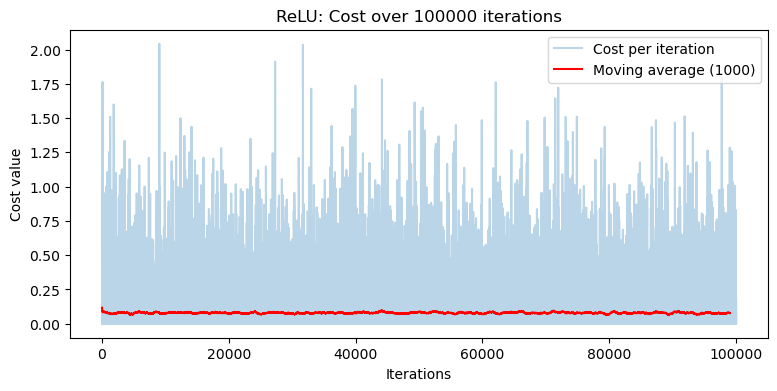

In [14]:
w1, w2, b, relu_costs = train(relu, relu_derivative)
plot_learning_curve(relu_costs, "ReLU")

In [15]:
relu_predictions = [relu(w1*p[0] + w2*p[1] + b) for p in array]
results['ReLU'] = (relu_costs, accuracy(relu_predictions))
print('w1:', w1, ' w2:', w2, ' b:', b)
print('Accuracy:', results['ReLU'][1])

w1: 0.2800663204818542  w2: 0.39131822524183657  b: 0.5978326933015116
Accuracy: 0.9655172413793104


### Experiment 3: Tanh

Tanh is shaped like sigmoid but gives values between -1 and 1 and is centred on 0. Its derivative is 1 minus tanh squared.

In [16]:
def tanh(z):
    return np.tanh(z)

def tanh_derivative(z):
    return 1 - np.tanh(z)**2

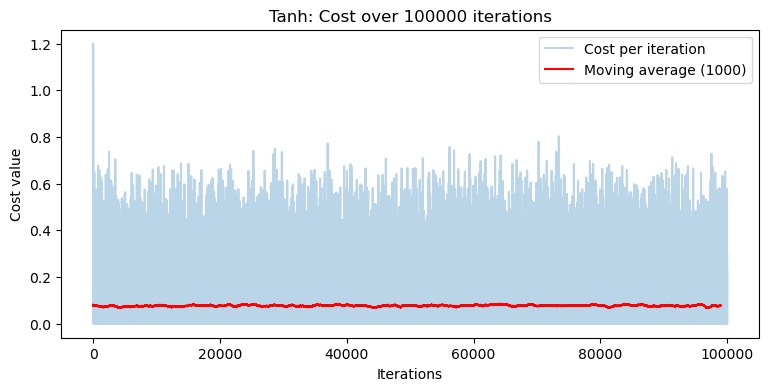

In [17]:
w1, w2, b, tanh_costs = train(tanh, tanh_derivative)
plot_learning_curve(tanh_costs, "Tanh")

In [18]:
tanh_predictions = [tanh(w1*p[0] + w2*p[1] + b) for p in array]
results['Tanh'] = (tanh_costs, accuracy(tanh_predictions))
print('w1:', w1, ' w2:', w2, ' b:', b)
print('Accuracy:', results['Tanh'][1])

w1: 0.10360157792297457  w2: 0.6329076122361177  b: 0.9489971168994744
Accuracy: 0.8620689655172413


### Experiment 4: Softmax

Softmax turns a list of scores into probabilities that add up to 1. With only one output neuron softmax would always give 1, so the network is changed to have two output neurons, one for Female and one for Male, each with its own weights and bias. The cost is still the squared error on the Male probability so it can be compared with the other three.

The derivative of the Male probability with respect to the Male score is p_male(1 - p_male), and with respect to the Female score it is -p_male * p_female.

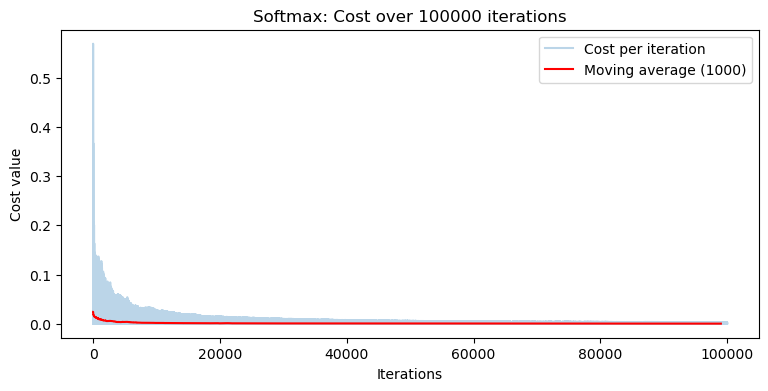

In [19]:
def softmax(scores):
    exps = np.exp(scores - np.max(scores))
    return exps / exps.sum()

np.random.seed(12345)
#Row 0 is the Female neuron and row 1 is the Male neuron, columns are w1, w2, b
weights = np.random.randn(2, 3)

softmax_costs = []

for i in range(iterations):
    random_number = np.random.randint(len(array))
    random_person = array[random_number]

    inputs = np.array([random_person[0], random_person[1], 1]) #height, weight and 1 for the bias
    actualGender = random_person[2]

    scores = weights @ inputs
    probabilities = softmax(scores)
    p_female = probabilities[0]
    p_male = probabilities[1]

    cost = (p_male - actualGender)**2
    softmax_costs.append(cost)

    dcost_dp_male = 2*(p_male - actualGender)
    dp_male_dscores = np.array([-p_male * p_female, p_male * (1 - p_male)])

    dcost_dscores = dcost_dp_male * dp_male_dscores
    dcost_dweights = np.outer(dcost_dscores, inputs)

    weights = weights - learning_rate * dcost_dweights

plot_learning_curve(softmax_costs, "Softmax")

In [20]:
softmax_predictions = [softmax(weights @ np.array([p[0], p[1], 1]))[1] for p in array]
results['Softmax'] = (softmax_costs, accuracy(softmax_predictions))
print(weights)
print('Accuracy:', results['Softmax'][1])

[[-1.37852517 -4.68834965 -1.10529171]
 [ 0.6180872   7.13307356  1.97925883]]
Accuracy: 1.0


### Comparing all four

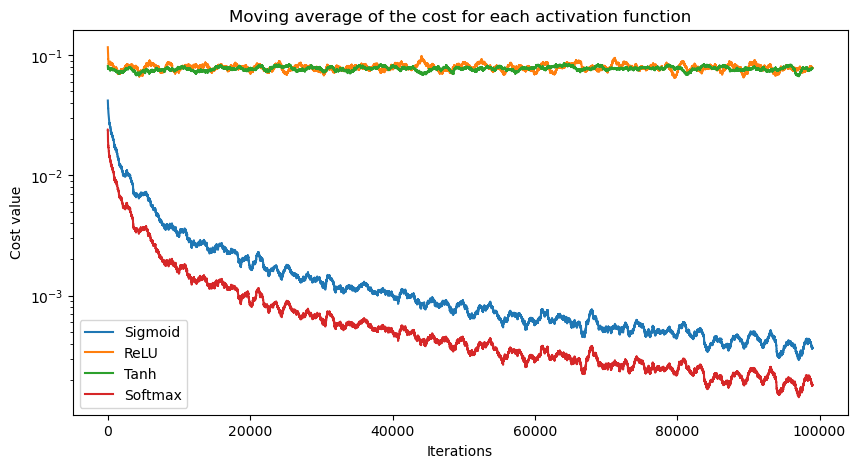

In [21]:
plt.figure(figsize = (10, 5))
for name, (costs, acc) in results.items():
    plt.plot(np.convolve(costs, np.ones(1000)/1000, mode = 'valid'), label = name)
plt.title("Moving average of the cost for each activation function")
plt.xlabel("Iterations")
plt.ylabel("Cost value")
plt.yscale('log')
plt.legend()
plt.show()

In [22]:
for name, (costs, acc) in results.items():
    costs = np.array(costs)
    print(f"{name:8} first 1000 avg cost: {costs[:1000].mean():.4f}   last 1000 avg cost: {costs[-1000:].mean():.6f}   accuracy: {acc:.2%}")

Sigmoid  first 1000 avg cost: 0.0420   last 1000 avg cost: 0.000371   accuracy: 100.00%
ReLU     first 1000 avg cost: 0.1166   last 1000 avg cost: 0.078054   accuracy: 96.55%
Tanh     first 1000 avg cost: 0.0814   last 1000 avg cost: 0.077976   accuracy: 86.21%
Softmax  first 1000 avg cost: 0.0241   last 1000 avg cost: 0.000183   accuracy: 100.00%


## Report

#### The four learning curves

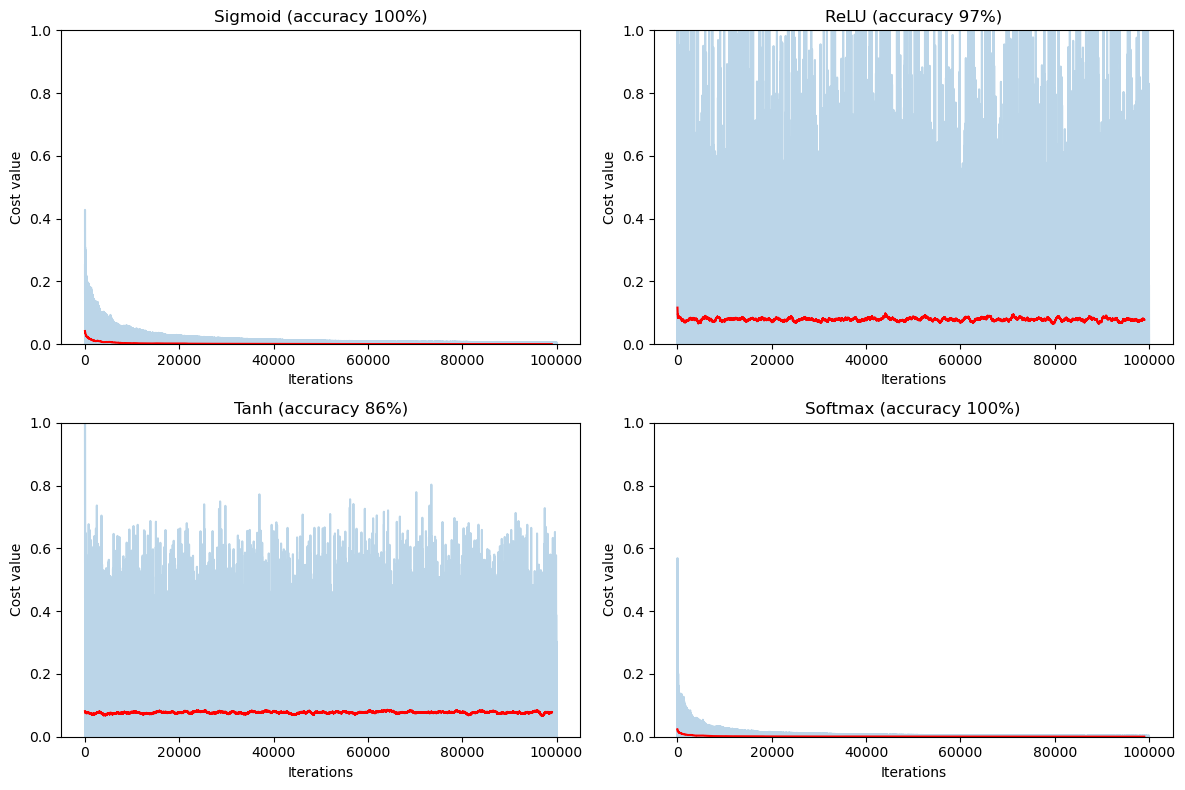

In [23]:
fig, axes = plt.subplots(2, 2, figsize = (12, 8))
axes = axes.flatten()

for ax, (name, (costs, acc)) in zip(axes, results.items()):
    ax.plot(costs, alpha = 0.3)
    ax.plot(np.convolve(costs, np.ones(1000)/1000, mode = 'valid'), c = 'r')
    ax.set_title(f"{name} (accuracy {acc:.0%})")
    ax.set_xlabel("Iterations")
    ax.set_ylabel("Cost value")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

All four networks were trained on the same 29 people with the same starting weights, the same learning rate of 0.1 and the same 100000 iterations. The only thing that changed was the activation function on the output, so any difference in the curves comes from the activation function itself. The light blue line in each plot is the cost for the single person picked at that iteration, which is why it is so spiky, and the red line is the moving average which shows the real trend.

#### How each activation function performed

**Sigmoid** learned well. The average cost started at about 0.042 over the first 1000 iterations and kept dropping the whole way to about 0.0004 by the end. The curve falls quickly in the first 10000 iterations and then keeps slowly creeping down, which shows the model was still improving even at 100000 iterations. It classified all 29 people correctly, and its predictions were very close to 0 for the females and very close to 1 for the males.

**ReLU** dropped quickly in the first 1000 iterations, from about 0.117 to 0.076, but then went completely flat and stayed around 0.075 to 0.085 for the rest of training. It still got 28 out of 29 people right (96.6%), but the predictions themselves were poor. Some females were given values like 0.4 and 0.56 and some males were given values above 1, like 1.92, which is not possible for a probability. So the model found roughly the right dividing line but could not produce clean answers.

**Tanh** was the weakest. Its curve was flat almost from the very start at around 0.075 to 0.08 and never really improved. It only got 25 out of 29 correct (86.2%). Most of the females were predicted somewhere between 0.24 and 0.54 instead of close to 0.

**Softmax** performed the best. It started with the lowest cost of about 0.024 and finished with the lowest cost of about 0.00018, which is roughly half of what sigmoid ended on. Its curve has the same shape as sigmoid but sits lower the whole way. It also got all 29 people correct.

In the comparison plot above, which uses a log scale, the difference is clear. Sigmoid and softmax keep going down, while ReLU and tanh level off at about 100 times higher cost and stay there.

#### Why some activation functions did so much better

The main reason is how well the output range of each activation function matches the labels. The labels are 0 for Female and 1 for Male, and the cost is the squared difference between the prediction and the label.

Sigmoid gives an output between 0 and 1, which is exactly the range of the labels. As the weights get bigger, the outputs get pushed closer and closer to 0 or 1, so the model can always lower the cost a little more by growing the weights. That is why the sigmoid weights ended up large (w2 was about 10.5) and why the curve keeps going down slowly instead of stopping.

Softmax with two outputs works in almost the same way. With two classes the Male probability from softmax works out to be the same as a sigmoid of the difference between the Male score and the Female score. So it is really doing the same job as sigmoid, which is why the two curves look so alike. It did slightly better because it has two sets of weights that both get updated each step, one pushing the Male score up and the other pushing the Female score down. This makes the gap between them grow about twice as fast, so it behaves a bit like sigmoid with a higher learning rate and gets further in the same number of iterations.

Tanh has the same S shape as sigmoid, but its output goes from minus 1 to 1, so 0 is right in the middle of its range instead of at the edge. For the females the model needs an output of exactly 0, which means z has to be exactly 0, while for the males it needs z to be large. A single straight line through the data cannot make z equal 0 for every female and large for every male at the same time. The best it can do is a compromise, which is why the cost gets stuck at around 0.078. This is a problem with the labels rather than with tanh itself. If the labels were changed to minus 1 for Female and 1 for Male, tanh would have the same advantage that sigmoid has.

ReLU has a similar problem in a different way. Its output can be anything from 0 upwards, with no upper limit. For the females the model can simply make z negative and the output becomes 0, which is perfect. But for the males the output needs to be exactly 1, and since ReLU is just a straight line for positive values, the output for males is basically z itself. It cannot flatten out at 1 the way sigmoid does, so taller and heavier males get predictions above 1 and shorter males get predictions below 1, and there is always some error left over. On top of that, once a person's z is negative the ReLU derivative is 0, so those people stop contributing to the updates at all. This is the dying ReLU problem, and it is why ReLU learned fast at the start and then stopped improving.

#### Conclusion

For this problem, where the network has one layer and has to give a yes or no answer between 0 and 1, sigmoid and softmax are clearly the right choices because their outputs are made to look like probabilities. Softmax did the best overall, and it would be the one to use if there were more than two classes. ReLU and tanh are not bad activation functions. ReLU is the most common choice for hidden layers in deep networks and tanh works well when the data is centred around 0. They just are not suited to being the final output for 0 and 1 labels with squared error cost, and the flat learning curves show exactly that.
